# Session 3

In [1]:
import numpy as np
from matplotlib import pyplot as plt
from IPython.display import display, Audio

from scipy.io import wavfile
from scipy import fftpack as fft
from scipy.signal import get_window

In [2]:
WAV_PATH = './sample_audio.wav'
display(Audio(WAV_PATH))

In [3]:
sample_rate, audio = wavfile.read(WAV_PATH)
duration = len(audio)/sample_rate

print(duration)

15.48


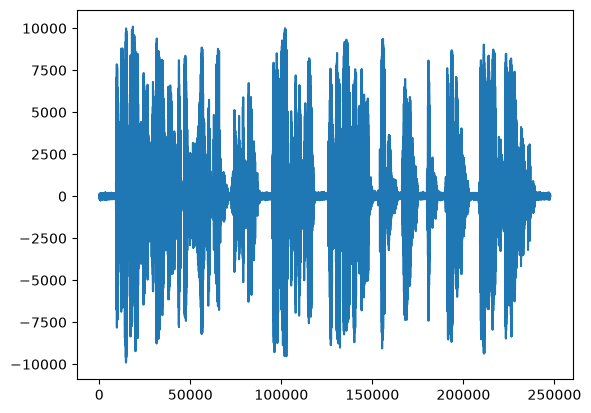

In [4]:
plt.plot(audio)
plt.show()

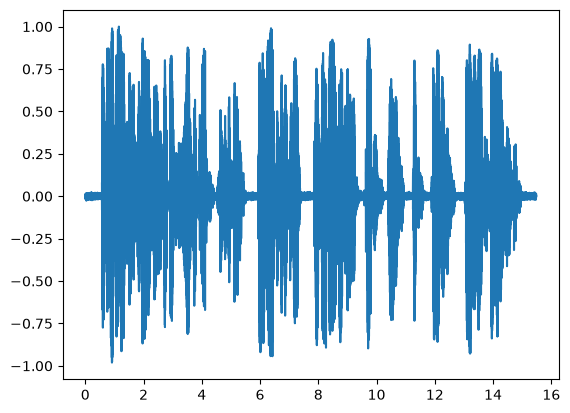

In [5]:
# Normalization
audio = audio / np.max(np.abs(audio))
plt.plot(np.linspace(0, duration, num=len(audio)), audio)
plt.show()

In [6]:
def framing(audio, sample_rate, fft_size, hop_size):
    # [1,2,3]
    # [2,1,2,3,2]
    # 2=4
    audio = np.pad(audio, int(fft_size/2), mode='reflect')
    
    frame_len = np.round(sample_rate * (hop_size/1000)).astype(int)
    frame_num = int((len(audio) - fft_size) / frame_len) + 1
    
    frames = np.zeros((frame_num, fft_size))
    for i in range(frame_num):
        frames[i] = audio[i * frame_len: i * frame_len + fft_size]

    return frames

In [7]:
hop_size = 15
fft_size = 2048
audio_frames = framing(audio, sample_rate, fft_size, hop_size)
audio_frames.shape

(1033, 2048)

In [8]:
window = get_window('hann',fft_size, fftbins=True)
audio_window = window * audio_frames

# np.transpose
# audio_window_T = np.transpose(audio_window)
audio_window_T = audio_window.T
audio_window_T.shape

(2048, 1033)

In [9]:
fft_res = np.empty((int(fft_size/2) + 1, audio_window_T.shape[1]), dtype=np.complex64, order='F')

for i in range(fft_res.shape[1]):
    fft_res[:,i] = fft.fft(audio_window_T[:,i], axis=0)[:fft_res.shape[0]]

fft_res = fft_res.T
fft_res.shape

(1033, 1025)

In [10]:
power_fft = np.square(fft_res)
power_fft = np.abs(power_fft)
power_fft

array([[4.93757892e-03, 9.09129009e-02, 1.31005466e+00, ...,
        4.94995538e-06, 5.90180454e-04, 2.51779496e-03],
       [2.20393538e-02, 3.89548168e-02, 1.57653534e+00, ...,
        1.27532201e-06, 5.35970670e-04, 2.82701128e-03],
       [3.29906325e-04, 1.81709439e-03, 1.94225192e+00, ...,
        4.78135407e-05, 7.70621002e-04, 3.35284532e-03],
       ...,
       [9.70152438e-01, 6.57936692e-01, 5.59557438e+00, ...,
        1.17263175e-04, 9.99460579e-04, 2.62805726e-03],
       [2.48477578e+00, 2.78968692e+00, 6.79662609e+00, ...,
        1.66580008e-04, 4.49086161e-04, 1.95111427e-03],
       [2.61400318e+00, 4.64156485e+00, 6.80777407e+00, ...,
        1.60369615e-04, 1.17162119e-04, 1.73250178e-03]],
      shape=(1033, 1025), dtype=float32)

# Session 4

In [11]:
# Function convert frq to mel dan sebaliknya
def freq_to_mel(freq):
	return 2595 * np.log10(1 + freq/700)

In [12]:
def mel_to_freq(mel):
	return (10 ** (mel / 2595) - 1) * 700

In [13]:
def get_filter_points(freqmin, freqmax, filter_num, sample_rate, fft_size):
    freqmin_mel = freq_to_mel(freqmin)
    freqmax_mel = freq_to_mel(freqmax)

    mels = np.linspace(freqmin_mel, freqmax_mel, filter_num + 2)
    freqs = mel_to_freq(mels)
    return ((fft_size + 1) / sample_rate * freqs).astype(int), freqs

In [14]:
freqmin = 0
freqmax = sample_rate / 2
filter_num = 10
filter_points, freqs = get_filter_points(freqmin, freqmax, filter_num, sample_rate, fft_size)

print(filter_points)
print(freqs)

[   0   23   52   88  134  192  264  355  470  614  796 1024]
[   0.          180.21928115  406.83711843  691.7991039  1050.12629534
 1500.70701371 2067.29249375 2779.74887082 3675.63149949 4802.16459006
 6218.73051459 8000.        ]


In [15]:
def get_filter(filter_points, fft_size):
    filters = np.zeros((len(filter_points) - 2, int(fft_size / 2) + 1))

    for i in range(len(filter_points) - 2):
        filters[i, filter_points[i]: filter_points[i + 1]] = np.linspace(
            0, 1, filter_points[i + 1] - filter_points[i]
        )
        
        filters[i, filter_points[i + 1]: filter_points[i + 2]] = np.linspace(
            1, 0, filter_points[i + 2] - filter_points[i + 1]
        )
    return filters

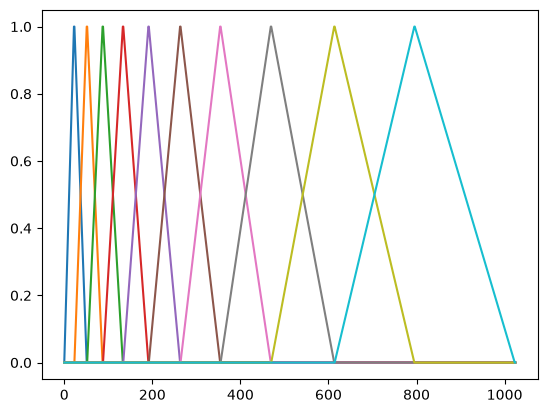

In [16]:
filters = get_filter(filter_points, fft_size)

for i in range(len(filters)):
    plt.plot(filters[i])

In [17]:
enorm = 2 / (freqs[2: 2 + filter_num] - freqs[:filter_num])
filters *= enorm[:, np.newaxis]
print(filters.shape, enorm.shape)

(10, 1025) (10,)


In [18]:
audio_filter = np.dot(filters, power_fft.T)

In [19]:
audio_log = 10 * np.log10(audio_filter)

In [20]:
# dct
def dct(dct_filter_num, filter_num):
    basis = np.empty((dct_filter_num, filter_num))
    
    # init baris 1 basisnya dengan 1 / akar(filter_num)
    basis[0,:] = 1 / np.sqrt(filter_num)
    samples = np.arange(1, filter_num * 2, 2) * np.pi / (filter_num * 2)
    
    for i in range(1, dct_filter_num):
        basis[i,:] = np.cos(samples * i) * np.sqrt(2 / filter_num)

    return basis

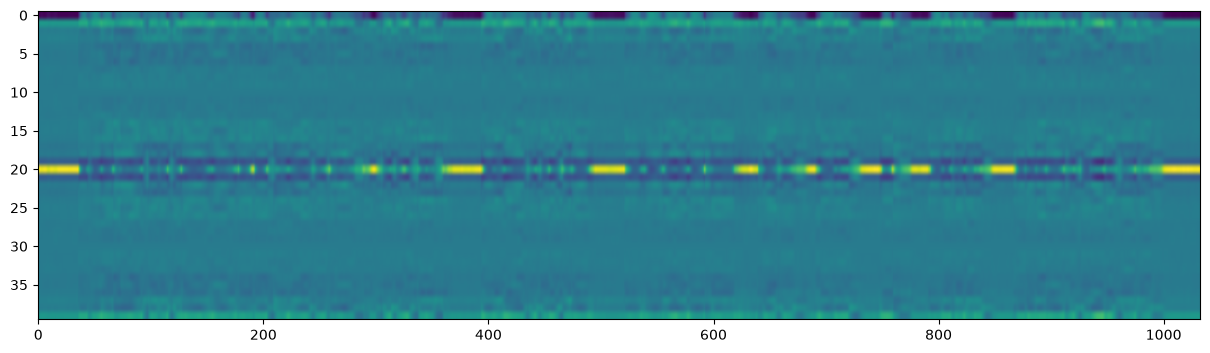

In [21]:
dct_filter_num = 40
dct_filters = dct(dct_filter_num, filter_num)
cepstral_coef = np.dot(dct_filters, audio_log)

plt.figure(figsize=(15, 4))
plt.imshow(cepstral_coef, aspect='auto')
plt.show()